<a href="https://colab.research.google.com/github/192412566/mechine-learning-lab/blob/main/Harini_Mech_Learn_Exp_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATASET
 X   Y
 1   3
 2   6
 3  11
 4  18
 5  27
 6  38
 7  51
 8  66
 9  83
10 102

MODEL EQUATIONS

Linear Regression:
Y = 11.0 X + -20.0

Polynomial Regression (Degree 2):
Y = 1.0 X² + -0.0 X + 2.0

MODEL PERFORMANCE COMPARISON
  Metric  Linear Regression  Polynomial Regression
     MAE             6.4000                    0.0
     MSE            52.8000                    0.0
    RMSE             7.2664                    0.0
R² Score             0.9498                    1.0


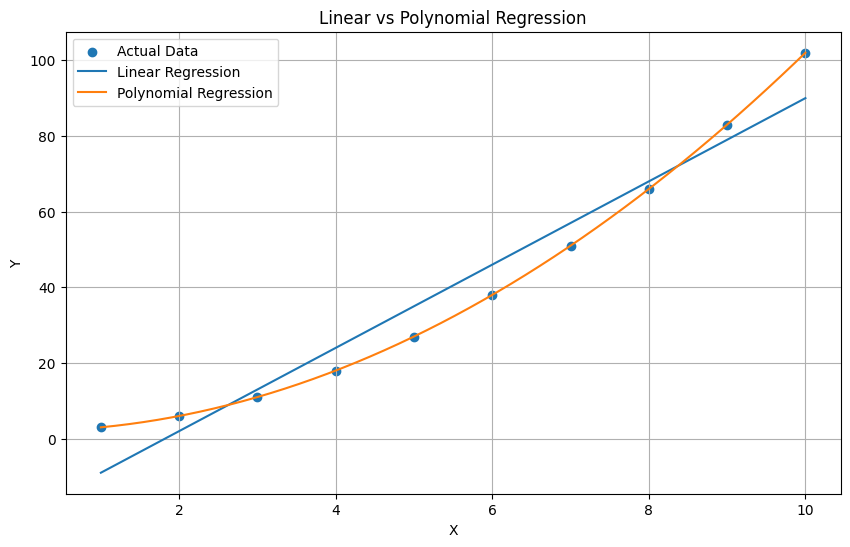


NEW SAMPLE PREDICTION
New X value: 7.5
Linear Regression Prediction: 62.5
Polynomial Regression Prediction: 58.25


NameError: name 'polynomial_r2' is not defined

In [1]:
# ============================================================
# COMPARISON OF LINEAR AND POLYNOMIAL REGRESSION
# Google Colab - No CSV Required
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ------------------------------------------------------------
# 1. Create Dataset
# ------------------------------------------------------------

# Non-linear dataset
X = np.array([
    1, 2, 3, 4, 5,
    6, 7, 8, 9, 10
]).reshape(-1, 1)

y = np.array([
    3, 6, 11, 18, 27,
    38, 51, 66, 83, 102
])

data = pd.DataFrame({
    'X': X.flatten(),
    'Y': y
})

print("DATASET")
print("=" * 50)
print(data.to_string(index=False))


# ------------------------------------------------------------
# 2. Linear Regression
# ------------------------------------------------------------

linear_model = LinearRegression()

linear_model.fit(
    X,
    y
)

linear_prediction = linear_model.predict(X)


# ------------------------------------------------------------
# 3. Polynomial Regression
# ------------------------------------------------------------

# Degree of polynomial
degree = 2

poly = PolynomialFeatures(
    degree=degree
)

X_poly = poly.fit_transform(X)

polynomial_model = LinearRegression()

polynomial_model.fit(
    X_poly,
    y
)

polynomial_prediction = polynomial_model.predict(
    X_poly
)


# ------------------------------------------------------------
# 4. Calculate Linear Regression Metrics
# ------------------------------------------------------------

linear_mae = mean_absolute_error(
    y,
    linear_prediction
)

linear_mse = mean_squared_error(
    y,
    linear_prediction
)

linear_rmse = np.sqrt(
    linear_mse
)

linear_r2 = r2_score(
    y,
    linear_prediction
)


# ------------------------------------------------------------
# 5. Calculate Polynomial Regression Metrics
# ------------------------------------------------------------

poly_mae = mean_absolute_error(
    y,
    polynomial_prediction
)

poly_mse = mean_squared_error(
    y,
    polynomial_prediction
)

poly_rmse = np.sqrt(
    poly_mse
)

poly_r2 = r2_score(
    y,
    polynomial_prediction
)


# ------------------------------------------------------------
# 6. Display Model Equations
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("MODEL EQUATIONS")
print("=" * 60)

print(
    "\nLinear Regression:"
)

print(
    "Y =",
    round(linear_model.coef_[0], 4),
    "X +",
    round(linear_model.intercept_, 4)
)


print(
    "\nPolynomial Regression (Degree 2):"
)

print(
    "Y =",
    round(polynomial_model.coef_[2], 4),
    "X² +",
    round(polynomial_model.coef_[1], 4),
    "X +",
    round(polynomial_model.intercept_, 4)
)


# ------------------------------------------------------------
# 7. Compare Performance
# ------------------------------------------------------------

comparison = pd.DataFrame({
    'Metric': [
        'MAE',
        'MSE',
        'RMSE',
        'R² Score'
    ],

    'Linear Regression': [
        linear_mae,
        linear_mse,
        linear_rmse,
        linear_r2
    ],

    'Polynomial Regression': [
        poly_mae,
        poly_mse,
        poly_rmse,
        poly_r2
    ]
})

print("\n" + "=" * 60)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 60)

print(
    comparison.round(4).to_string(index=False)
)


# ------------------------------------------------------------
# 8. Plot Both Models
# ------------------------------------------------------------

X_curve = np.linspace(
    1,
    10,
    200
).reshape(-1, 1)

linear_curve = linear_model.predict(
    X_curve
)

poly_curve = polynomial_model.predict(
    poly.transform(X_curve)
)


plt.figure(figsize=(10, 6))

# Actual data
plt.scatter(
    X,
    y,
    label="Actual Data"
)

# Linear regression
plt.plot(
    X_curve,
    linear_curve,
    label="Linear Regression"
)

# Polynomial regression
plt.plot(
    X_curve,
    poly_curve,
    label="Polynomial Regression"
)

plt.xlabel("X")
plt.ylabel("Y")

plt.title(
    "Linear vs Polynomial Regression"
)

plt.legend()

plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 9. Predict a New Sample
# ------------------------------------------------------------

new_x = np.array([
    [7.5]
])

# Linear prediction
linear_new_prediction = linear_model.predict(
    new_x
)

# Polynomial prediction
poly_new_prediction = polynomial_model.predict(
    poly.transform(new_x)
)


print("\n" + "=" * 60)
print("NEW SAMPLE PREDICTION")
print("=" * 60)

print("New X value:", new_x[0][0])

print(
    "Linear Regression Prediction:",
    round(float(linear_new_prediction[0]), 2)
)

print(
    "Polynomial Regression Prediction:",
    round(float(poly_new_prediction[0]), 2)
)


# ------------------------------------------------------------
# 10. Determine Better Model
# ------------------------------------------------------------

if polynomial_r2 > linear_r2:
    print("\nBetter Model: Polynomial Regression")
else:
    print("\nBetter Model: Linear Regression")